# iFood-2019 | ML for Modelling - FULL Pipeline
**300 images/class, 128x128, SL=30 epochs, SSL=30 epochs**



## 0. Setup: Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_BASE = '/content/drive/MyDrive/SUP'
CODE_DIR   = os.path.join(DRIVE_BASE, 'code')
OUT_DIR    = os.path.join(DRIVE_BASE, 'outputs')
os.makedirs(CODE_DIR, exist_ok=True)
os.makedirs(OUT_DIR,  exist_ok=True)
print('Drive mounted!')

Mounted at /content/drive
Drive mounted!


## 1. Kaggle Authentication

In [ ]:
from google.colab import files
print('Upload kaggle.json:')
files.upload()

Upload kaggle.json:


Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"mirpouryarezaeisani","key":"27216fc5876ee25c909fe5685df0367e"}'}

In [ ]:
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
print('Kaggle credentials set up!')

Kaggle credentials set up!


## 2. Download & Extract Dataset


In [ ]:
%run $CODE_DIR/00_setup_data.py

100%|██████████| 2.84G/2.84G [02:26<00:00, 20.8MB/s]

Extracting files...


Downloaded/cached at: /root/.cache/kagglehub/competitions/ifood-2019-fgvc6 (172.4s)
Extracting train_set.zip ...
  Done in 36.7s
Extracting val_set.zip ...
  Done in 2.9s
Copied: train_labels.csv
Copied: val_labels.csv
Copied: class_list.txt

Final contents of /content/local_data
  class_list.txt
  train_labels.csv
  train_set/  (118475 files)
  val_labels.csv
  val_set/  (11994 files)

Data setup complete! Ready to run 01_data_preprocessing.py


## 3. Data Preprocessing & EDA
(300 images/class, 128x128)

In [ ]:
%run $CODE_DIR/01_data_preprocessing.py

  iFood-2019 | Data Preprocessing (FULL)
  300 images/class | 128x128
  Reading from LOCAL disk: /content/local_data
Train samples (full) : 118475
Classes             : 251
After sub-sampling: 74990 images (max 300 / class)
Train split : 63741 | Val split : 11249
Splits saved.
Saved: eda_class_distribution.png
Saved: eda_sample_grid.png

Preprocessing complete!
Total images needed locally: 74990


<Figure size 640x480 with 0 Axes>

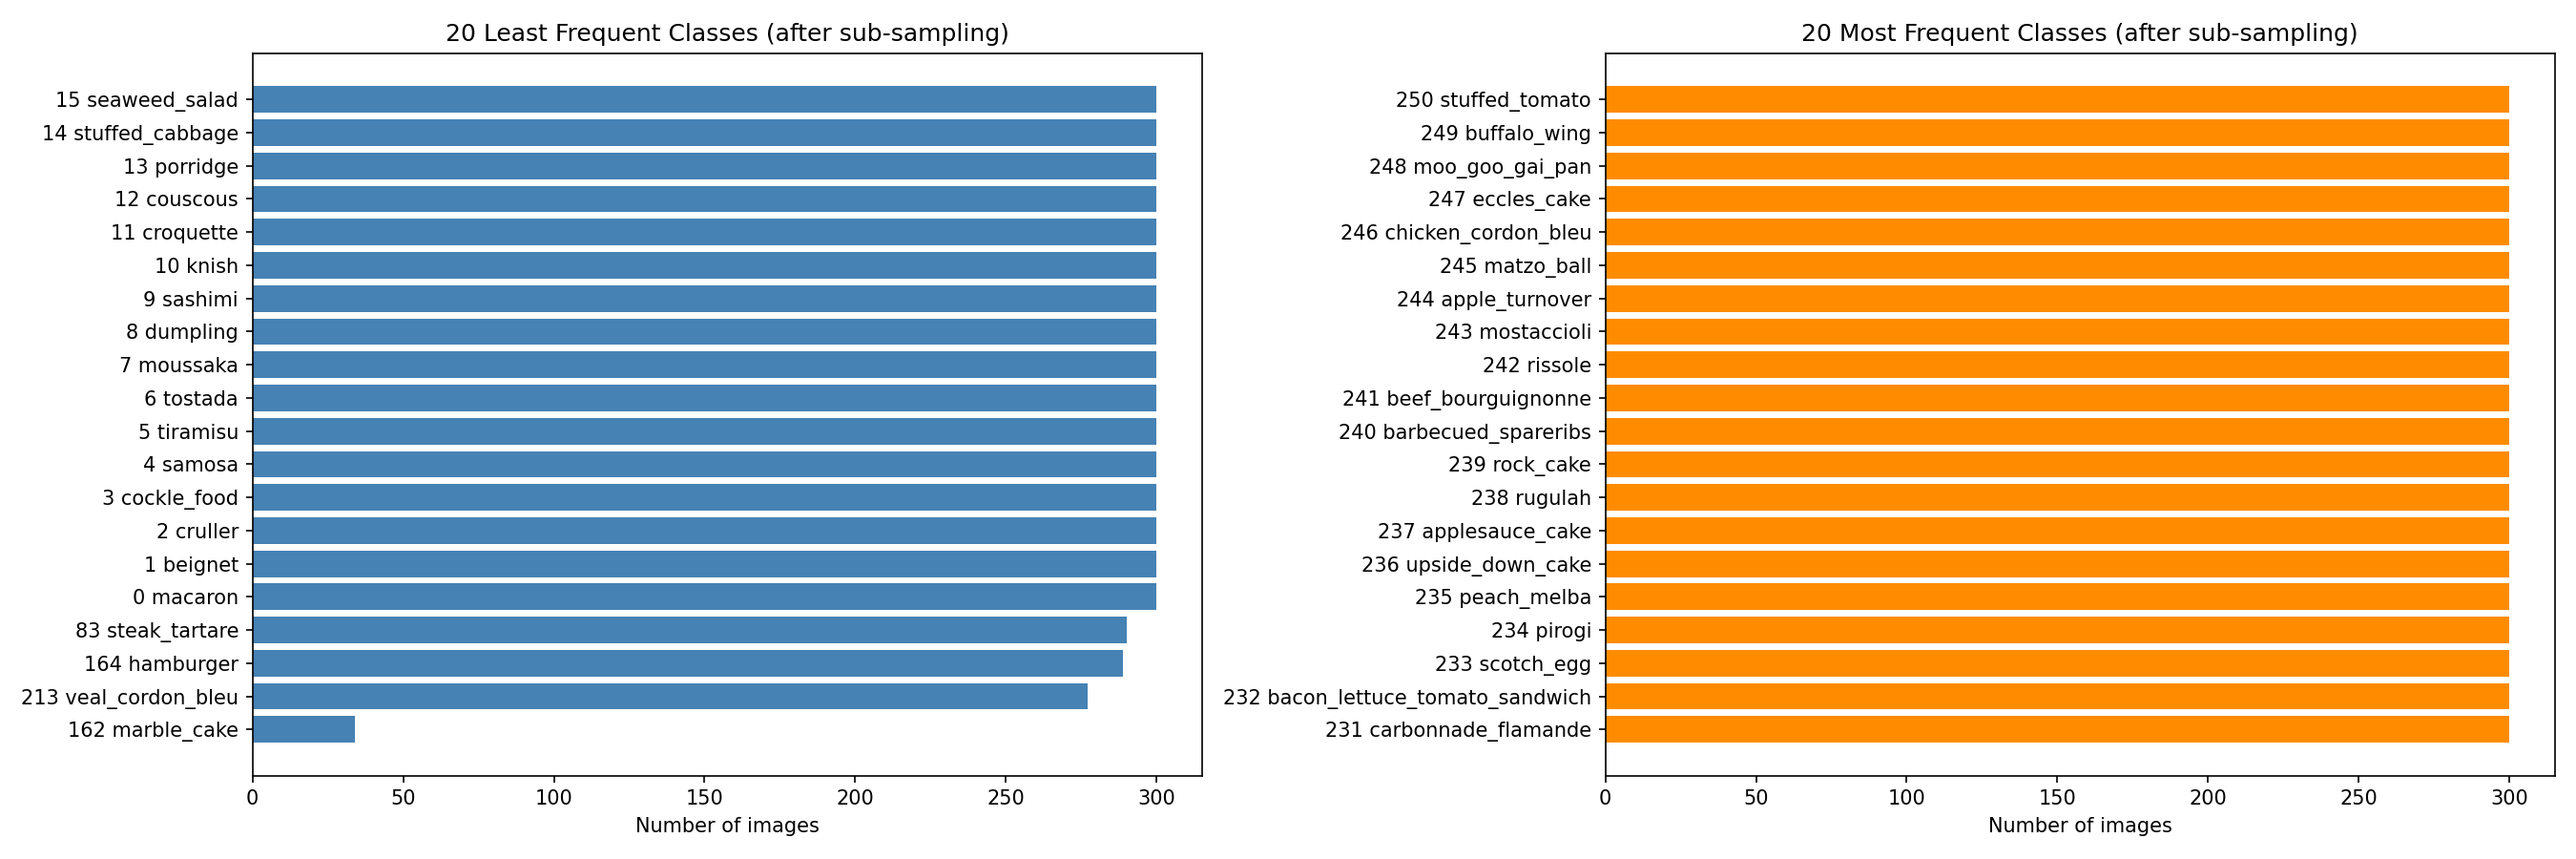

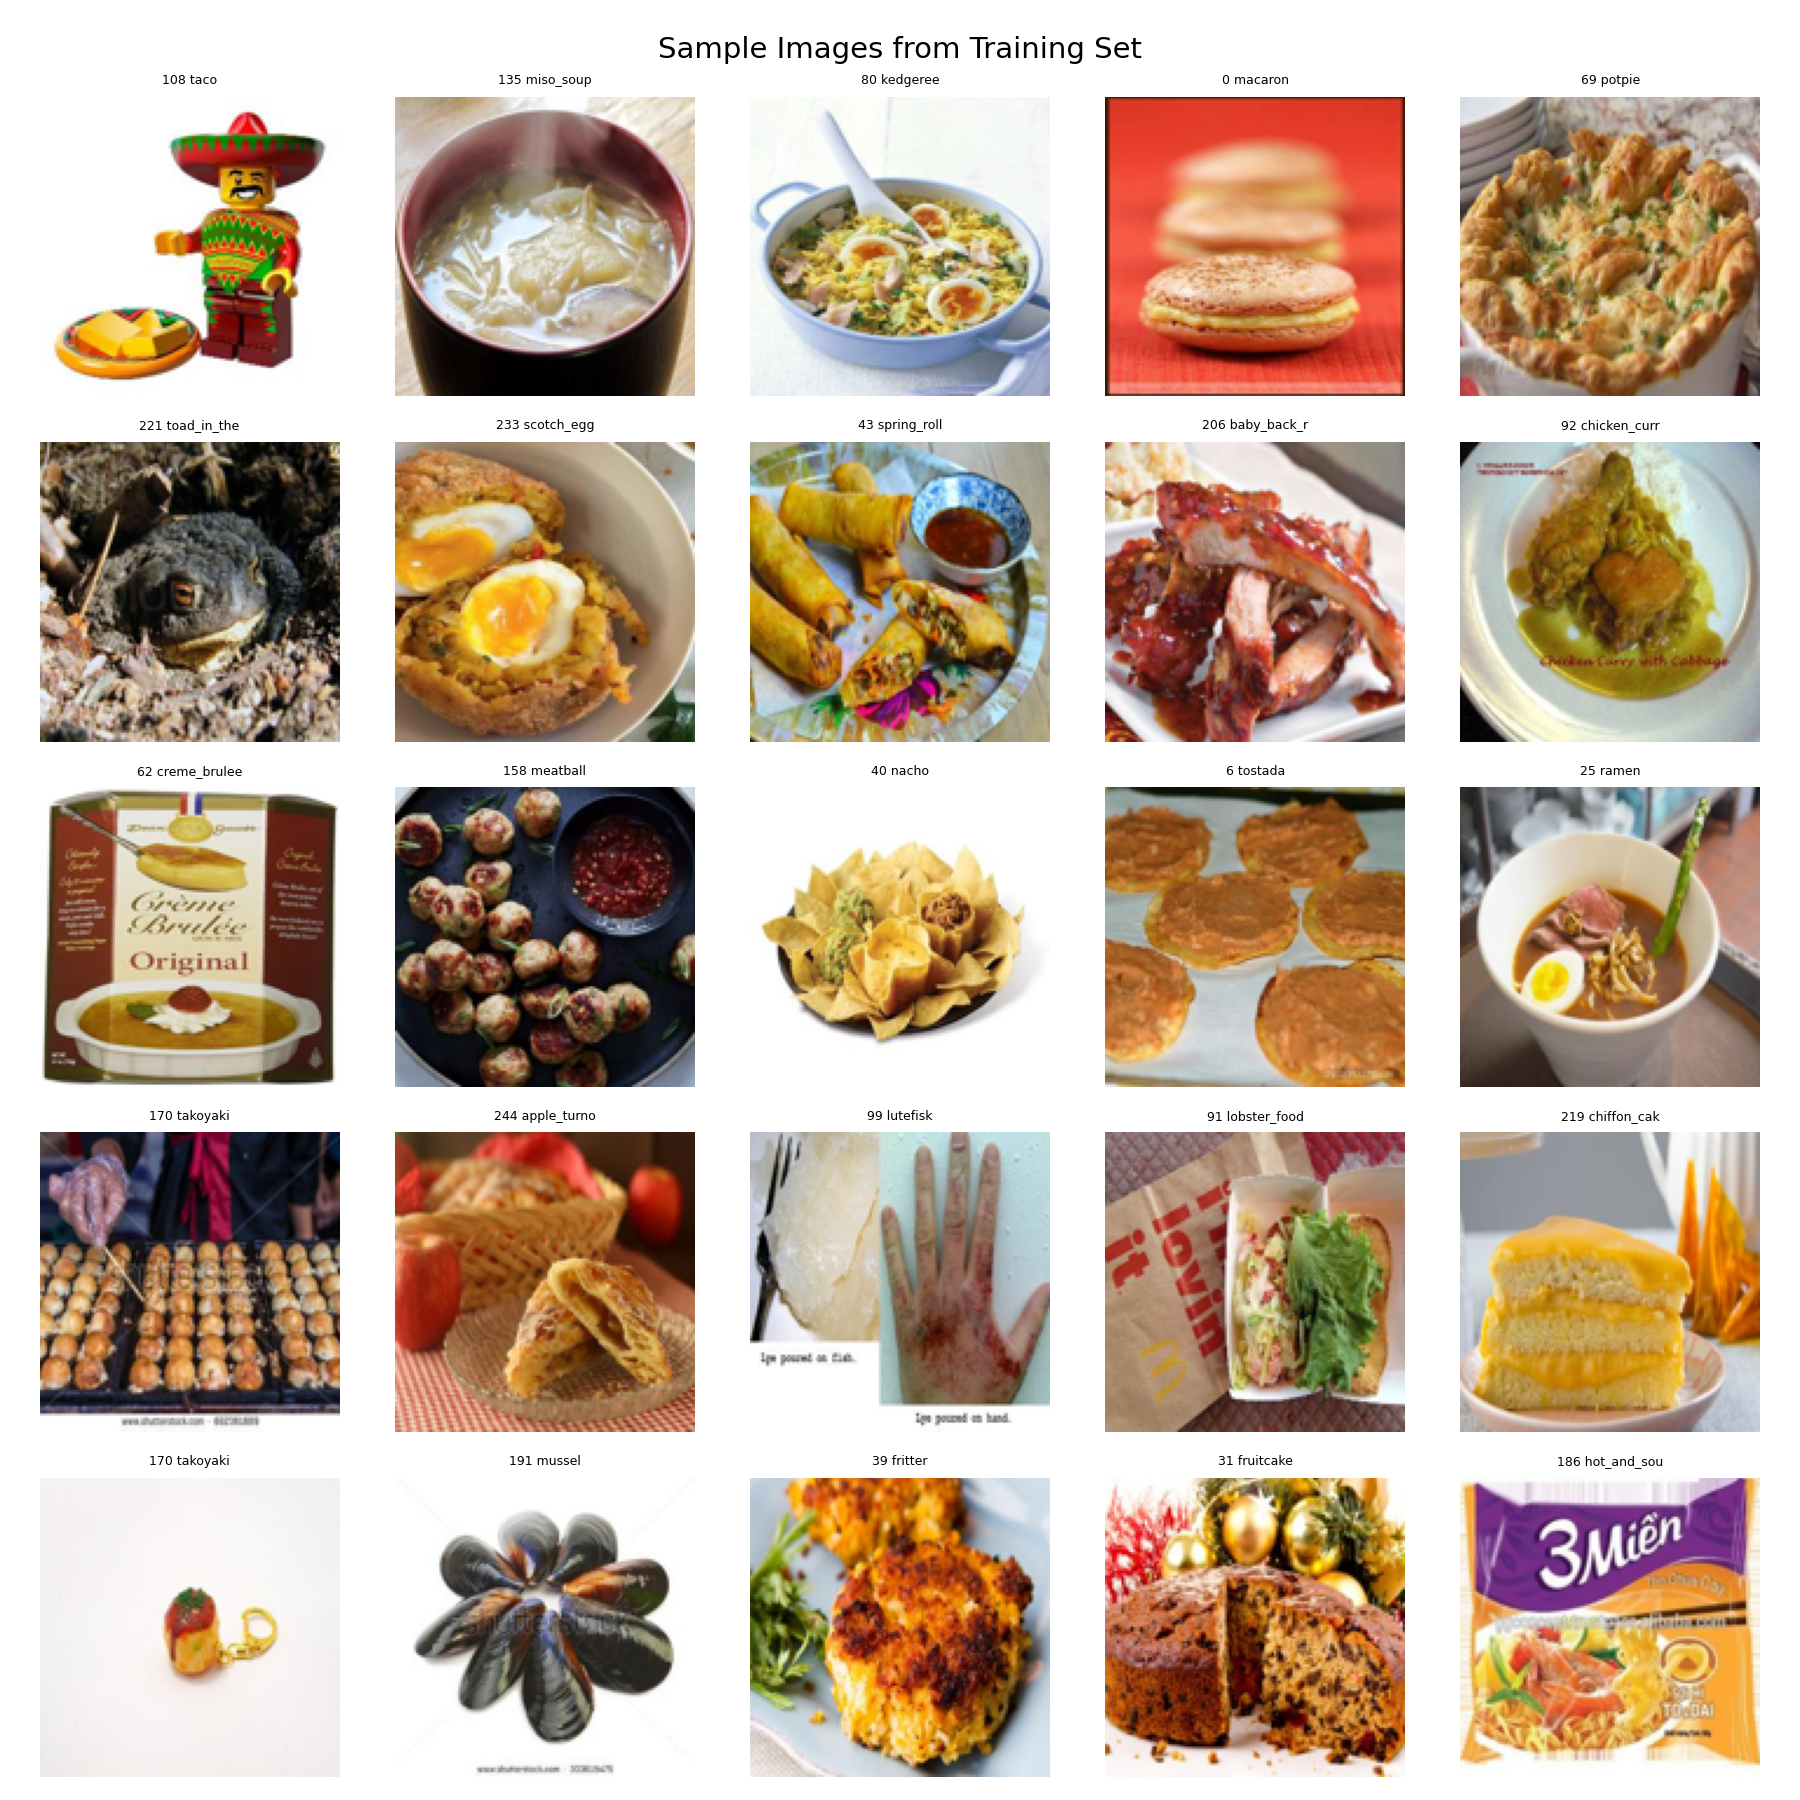

In [ ]:
from IPython.display import Image as IPImage, display
display(IPImage(os.path.join(OUT_DIR, 'eda_class_distribution.png')))
display(IPImage(os.path.join(OUT_DIR, 'eda_sample_grid.png')))

## 4. Model Architecture

In [ ]:
%run $CODE_DIR/02_model_architecture.py

Total parameters     : 704,123
Trainable parameters : 704,123
✅ Parameter constraint satisfied (< 10 M)

Input  : torch.Size([4, 3, 128, 128])
Output : torch.Size([4, 251])
Features: torch.Size([4, 256])


## 5. Supervised Learning Training (30 epochs)

In [ ]:
%run $CODE_DIR/03_supervised_training.py

Device: cuda
Training for max 30 epochs (early stopping patience=7)
  Supervised Learning - Training FoodNet (FULL)
Train batches: 995 | Val batches: 176
Total parameters     : 704,123
Trainable parameters : 704,123
✅ Parameter constraint satisfied (< 10 M)
Epoch 001/30 | Train Loss: 5.4632  Acc: 0.0072 | Val Loss: 5.3453  Acc: 0.0134 | 286.9s
  Model saved (val_loss=5.3453)
Epoch 002/30 | Train Loss: 5.2932  Acc: 0.0179 | Val Loss: 5.1772  Acc: 0.0255 | 286.3s
  Model saved (val_loss=5.1772)
Epoch 003/30 | Train Loss: 5.1414  Acc: 0.0306 | Val Loss: 5.0113  Acc: 0.0448 | 287.3s
  Model saved (val_loss=5.0113)
Epoch 004/30 | Train Loss: 4.9839  Acc: 0.0503 | Val Loss: 4.8276  Acc: 0.0713 | 299.9s
  Model saved (val_loss=4.8276)
Epoch 005/30 | Train Loss: 4.8197  Acc: 0.0695 | Val Loss: 4.6539  Acc: 0.0957 | 296.2s
  Model saved (val_loss=4.6539)
Epoch 006/30 | Train Loss: 4.6827  Acc: 0.0904 | Val Loss: 4.5163  Acc: 0.1190 | 294.8s
  Model saved (val_loss=4.5163)
Epoch 007/30 | Train L

<Figure size 640x480 with 0 Axes>

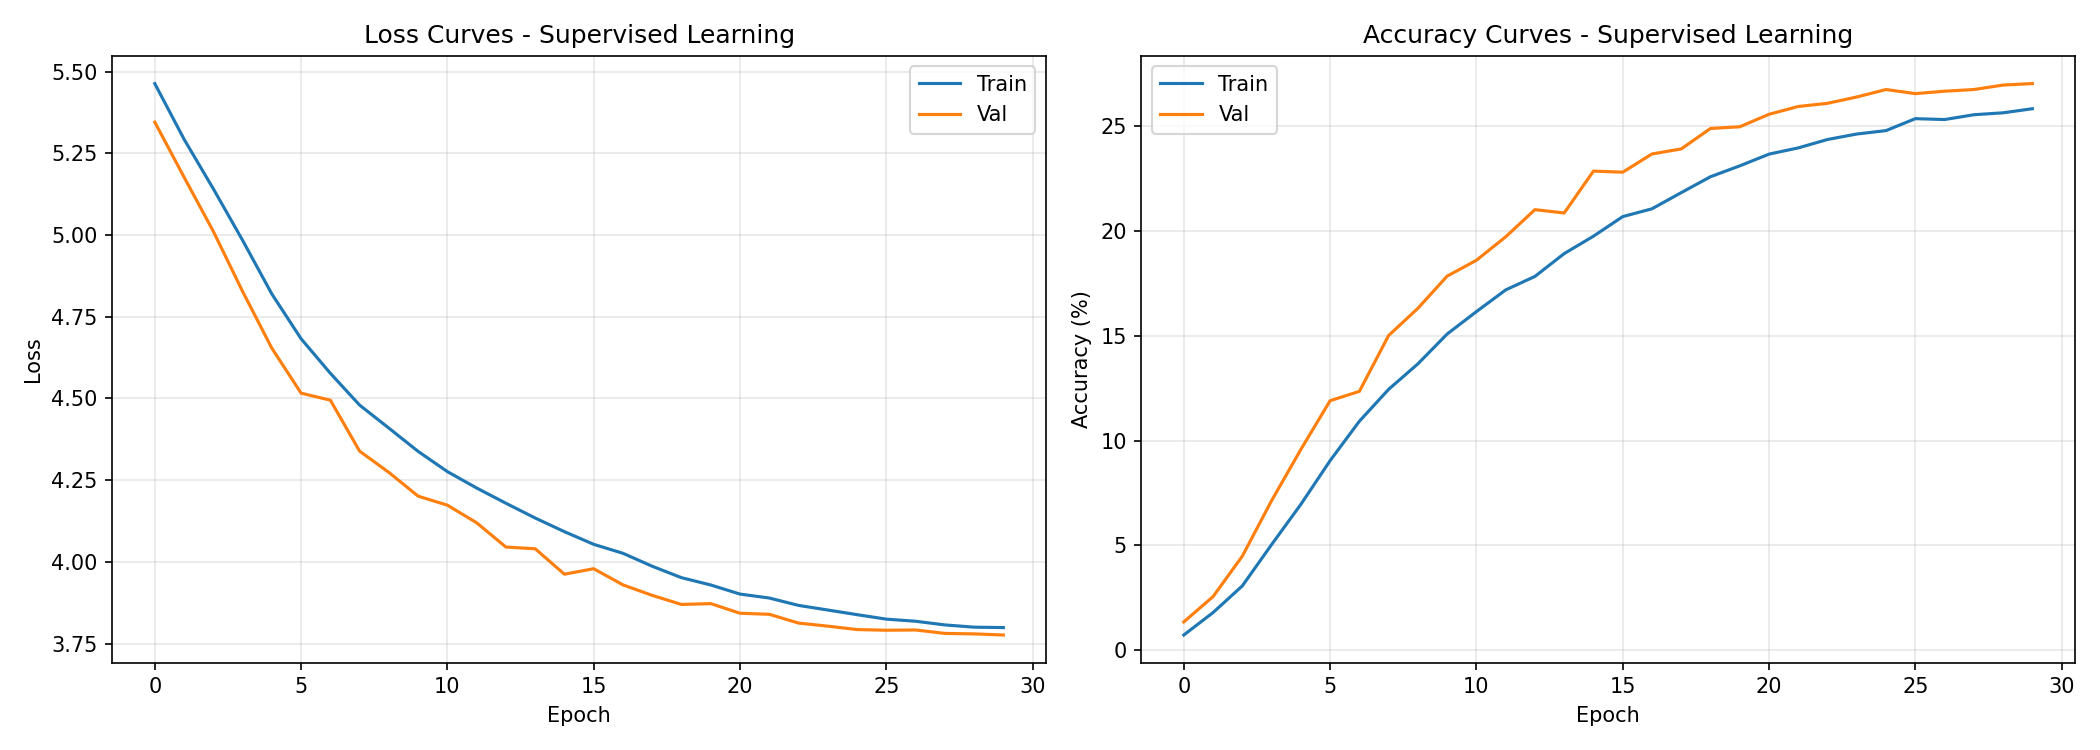

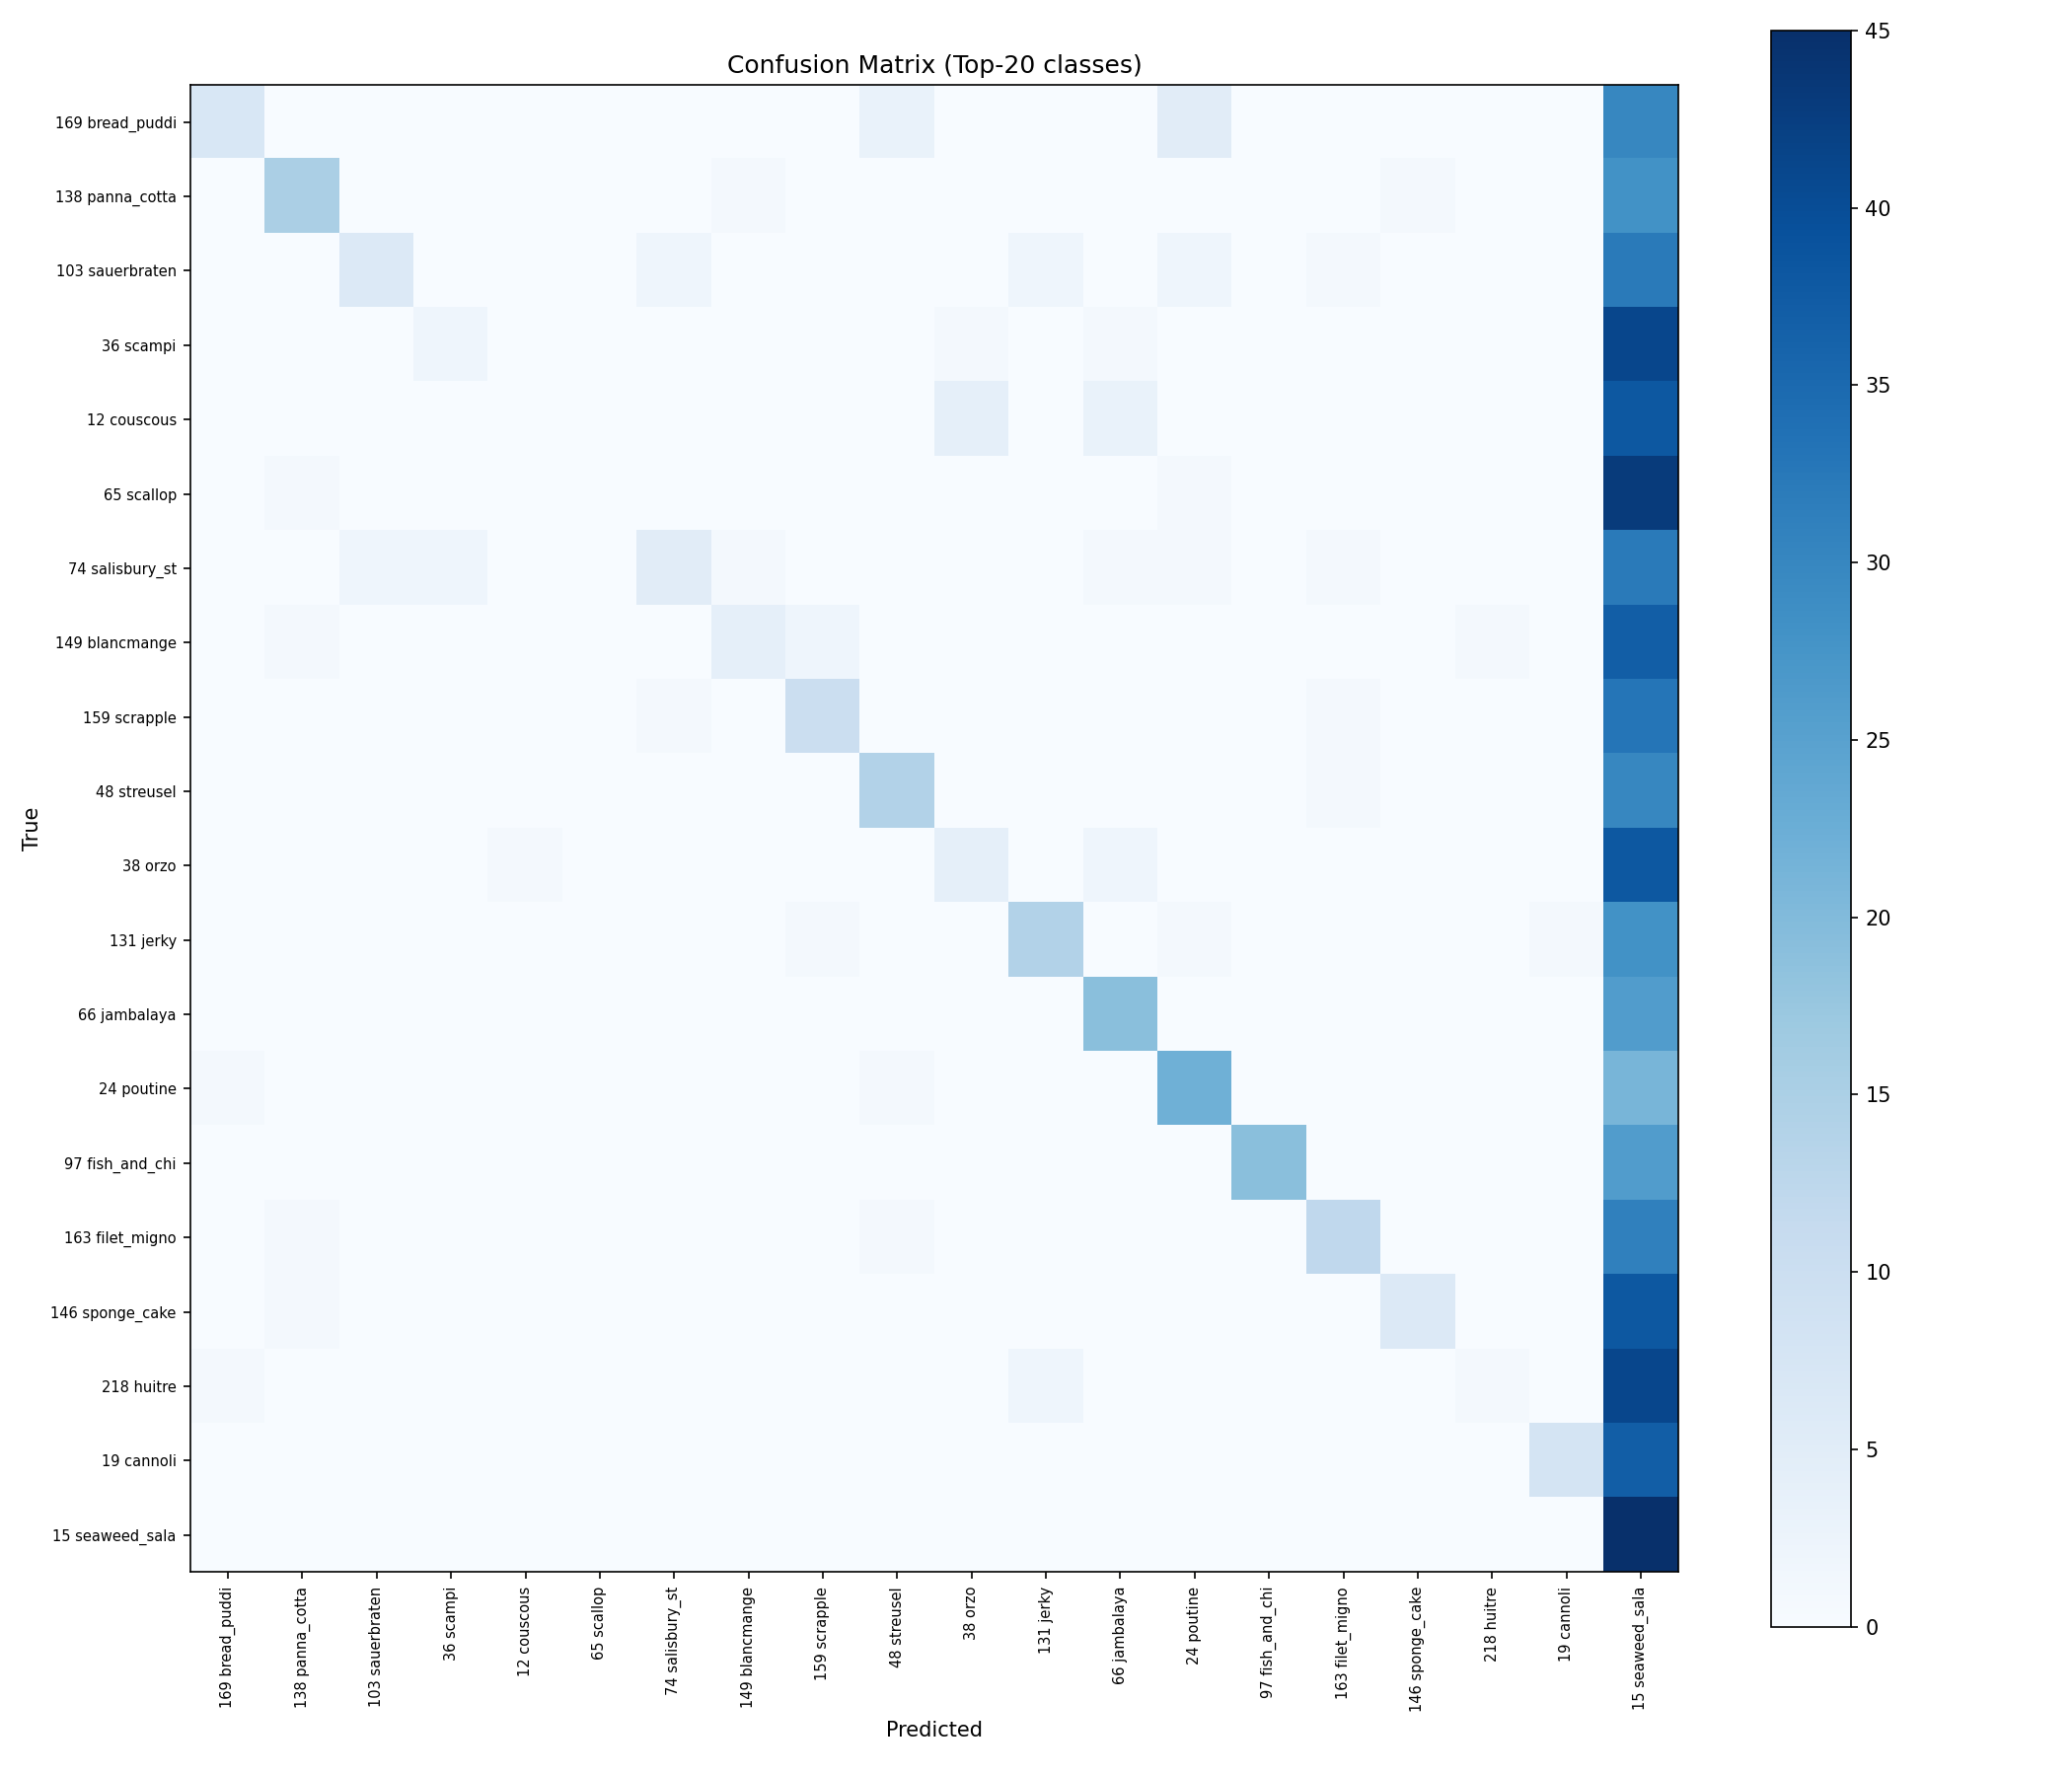

In [ ]:
display(IPImage(os.path.join(OUT_DIR, 'sl_training_curves.png')))
display(IPImage(os.path.join(OUT_DIR, 'sl_confusion_matrix.png')))

In [ ]:
import sys, os, time
sys.path.insert(0, '/content/drive/MyDrive/SUP/code')

import importlib.util
def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod  = importlib.util.module_from_spec(spec)
    sys.modules[name] = mod
    spec.loader.exec_module(mod)
    return mod

CODE = '/content/drive/MyDrive/SUP/code'
print("Step 1: loading modules...")
t0 = time.time()
data_preprocessing = load_module('data_preprocessing', f'{CODE}/01_data_preprocessing.py')
model_architecture  = load_module('model_architecture',  f'{CODE}/02_model_architecture.py')
print(f"  done in {time.time()-t0:.1f}s")

import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image

FoodNet        = model_architecture.FoodNet
get_transforms = data_preprocessing.get_transforms
NUM_CLASSES    = data_preprocessing.NUM_CLASSES
IMG_SIZE       = data_preprocessing.IMG_SIZE

DRIVE_BASE = '/content/drive/MyDrive/SUP'
OUT_DIR    = os.path.join(DRIVE_BASE, 'outputs')
TRAIN_DIR  = '/content/local_data/train_set'

SSL_BATCH = 128
SSL_LR    = 1e-3
SSL_TEMP  = 0.5
PROJ_DIM  = 128
NUM_WORKERS = 2

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Step 2: device = {device}")

print("Step 3: reading train_split.csv...")
t0 = time.time()
train_df = pd.read_csv(os.path.join(OUT_DIR, 'train_split.csv'))
print(f"  done in {time.time()-t0:.1f}s, rows={len(train_df)}")

class SSLFoodDataset(Dataset):
    def __init__(self, df, img_dir, transform):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.df.iloc[idx]['img_name'])
        try:
            img = Image.open(img_path).convert('RGB')
        except Exception:
            img = Image.new('RGB', (IMG_SIZE, IMG_SIZE), 0)
        views = self.transform(img)
        return views[0], views[1]

print("Step 4: creating dataset object...")
t0 = time.time()
ssl_ds = SSLFoodDataset(train_df, TRAIN_DIR, get_transforms('ssl'))
print(f"  done in {time.time()-t0:.1f}s")

print("Step 5: creating DataLoader...")
t0 = time.time()
ssl_loader = DataLoader(ssl_ds, batch_size=SSL_BATCH, shuffle=True,
                        num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
print(f"  done in {time.time()-t0:.1f}s (this just creates the object, doesn't load data yet)")
print(f"  total batches per epoch: {len(ssl_loader)}")

class ProjectionHead(nn.Module):
    def __init__(self, in_dim=256, hidden_dim=256, out_dim=PROJ_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim, bias=False),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, out_dim, bias=False),
            nn.BatchNorm1d(out_dim),
        )
    def forward(self, x):
        return self.net(x)

class SimCLRModel(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.backbone  = FoodNet(num_classes=num_classes, dropout=0.0)
        self.projector = ProjectionHead(in_dim=256)
    def forward(self, x):
        feat = self.backbone.extract_features(x)
        proj = self.projector(feat)
        return F.normalize(proj, dim=1)

print("Step 6: creating model and moving to GPU...")
t0 = time.time()
model = SimCLRModel().to(device)
print(f"  done in {time.time()-t0:.1f}s")

print("Step 7: creating optimizer/scheduler...")
t0 = time.time()
optimizer = torch.optim.AdamW(model.parameters(), lr=SSL_LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-5)
print(f"  done in {time.time()-t0:.1f}s")

print("Step 8: starting iteration over ssl_loader (this is where it may hang)...")
t0 = time.time()
model.train()
batch_count = 0
for v1, v2 in ssl_loader:
    if batch_count == 0:
        print(f"  First batch received after {time.time()-t0:.1f}s")
    v1, v2 = v1.to(device), v2.to(device)
    batch_count += 1
    if batch_count >= 3:
        print(f"  Got {batch_count} batches, total elapsed: {time.time()-t0:.1f}s")
        break

print("\nDiagnostic complete - no hang detected in this test.")

Step 1: loading modules...
  done in 4.6s
Step 2: device = cuda
Step 3: reading train_split.csv...
  done in 0.0s, rows=63741
Step 4: creating dataset object...
  done in 0.0s
Step 5: creating DataLoader...
  done in 0.0s (this just creates the object, doesn't load data yet)
  total batches per epoch: 497
Step 6: creating model and moving to GPU...
  done in 0.3s
Step 7: creating optimizer/scheduler...
  done in 0.0s
Step 8: starting iteration over ssl_loader (this is where it may hang)...
  First batch received after 3.7s
  Got 3 batches, total elapsed: 7.2s

Diagnostic complete - no hang detected in this test.


## 6. Self-Supervised Learning - SimCLR (30 epochs)

In [ ]:
%run $CODE_DIR/04_ssl_simclr.py

Device: cpu
Training for 30 epochs (full version, resumable)
Using local data path: /content/local_data/train_set
  Self-Supervised Learning - SimCLR Pre-training (RESUMABLE)
  Total epochs: 30

Found previous checkpoint - resuming training...
  Loaded backbone weights from epoch 30
  best_loss so far: 4.0594
  Loaded 30 previous loss values

SSL training already completed (30 epochs). Skipping.
Saved: /content/drive/MyDrive/SUP/outputs/ssl_loss_curve.png

  SSL Linear Probe Evaluation
Extracting training features ...
Extracting validation features ...

Training Linear SVM ...
  SVM  Acc=0.0920  F1=0.0670
Training k-NN (k=5) ...
  KNN  Acc=0.0358  F1=0.0326
SSL metrics saved.
Running t-SNE ...
Saved: /content/drive/MyDrive/SUP/outputs/ssl_tsne.png

All SSL outputs saved!


<Figure size 640x480 with 0 Axes>

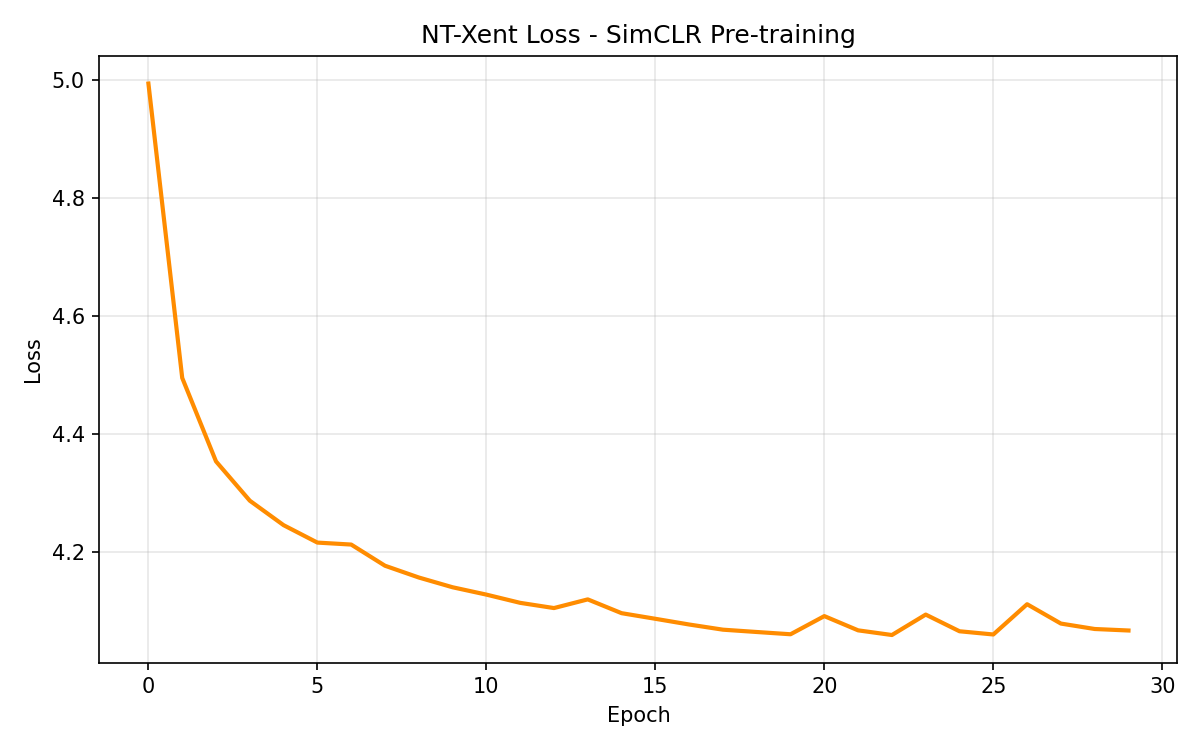

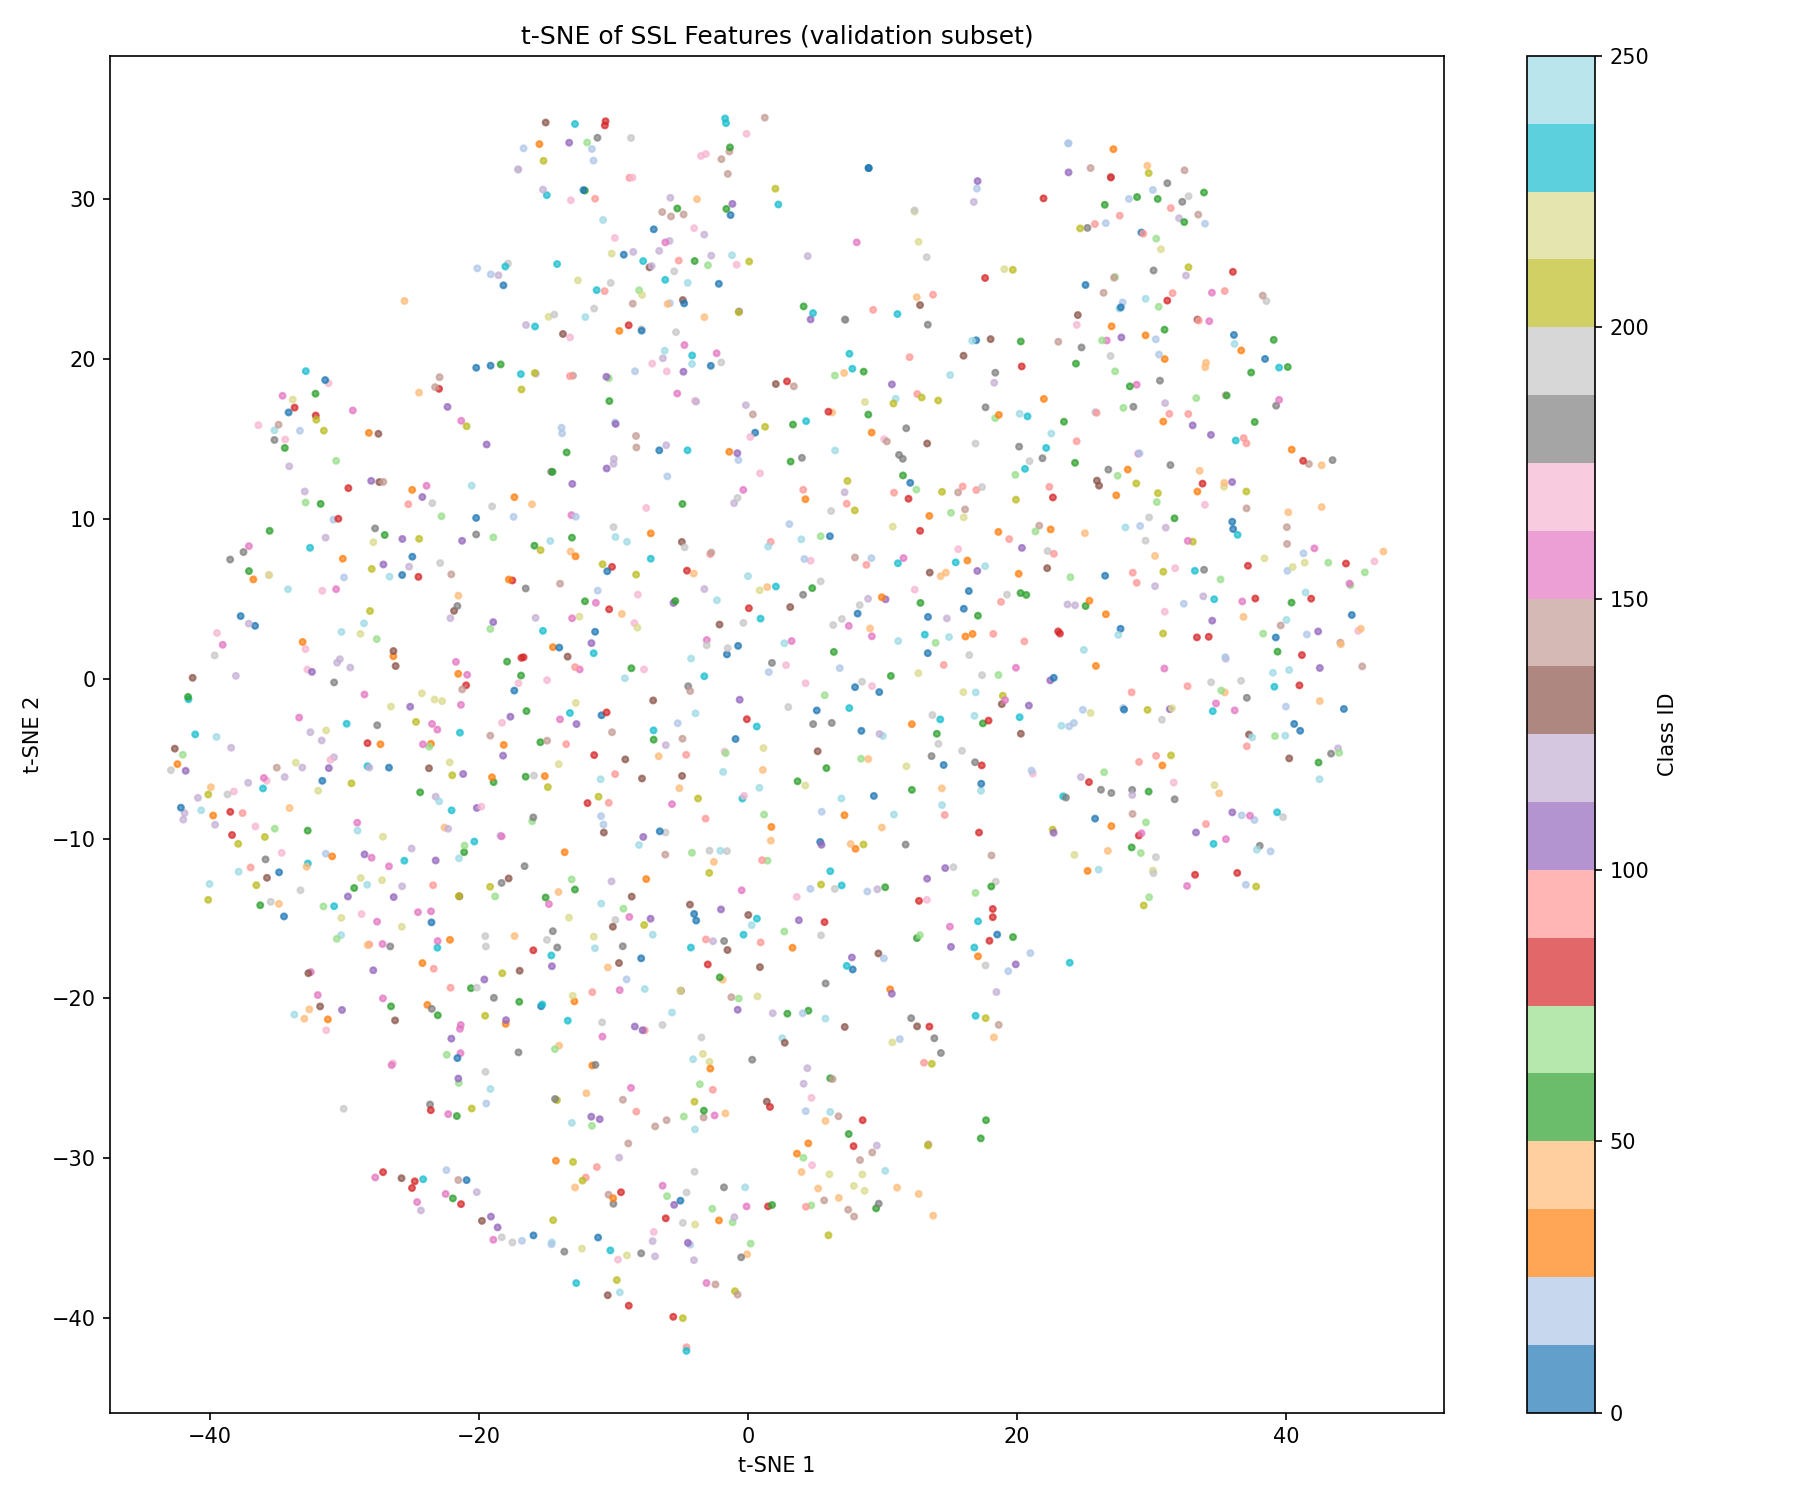

In [ ]:
display(IPImage(os.path.join(OUT_DIR, 'ssl_loss_curve.png')))
display(IPImage(os.path.join(OUT_DIR, 'ssl_tsne.png')))

## 7. Hyperparameter Tuning

In [ ]:
%run $CODE_DIR/05_hyperparameter_tuning.py

  Hyperparameter Tuning (RESUMABLE)
Grid search: 12 configurations
Found 12 previously completed configs - will skip those.
  [1/12] {'lr': 0.001, 'wd': 0.0001, 'dropout': 0.3, 'batch_size': 64} -> already done, skipping
  [2/12] {'lr': 0.001, 'wd': 0.0001, 'dropout': 0.4, 'batch_size': 64} -> already done, skipping
  [3/12] {'lr': 0.001, 'wd': 0.001, 'dropout': 0.3, 'batch_size': 64} -> already done, skipping
  [4/12] {'lr': 0.001, 'wd': 0.001, 'dropout': 0.4, 'batch_size': 64} -> already done, skipping
  [5/12] {'lr': 0.003, 'wd': 0.0001, 'dropout': 0.3, 'batch_size': 64} -> already done, skipping
  [6/12] {'lr': 0.003, 'wd': 0.0001, 'dropout': 0.4, 'batch_size': 64} -> already done, skipping
  [7/12] {'lr': 0.003, 'wd': 0.001, 'dropout': 0.3, 'batch_size': 64} -> already done, skipping
  [8/12] {'lr': 0.003, 'wd': 0.001, 'dropout': 0.4, 'batch_size': 64} -> already done, skipping
  [9/12] {'lr': 0.005, 'wd': 0.0001, 'dropout': 0.3, 'batch_size': 64} -> already done, skipping
  [10/1

<Figure size 640x480 with 0 Axes>

              Method  Accuracy  Precision   Recall  F1-score
FoodNet (Supervised)  0.270424   0.251349 0.269431  0.247333
          SimCLR + 0  0.092008   0.074912 0.091673  0.067035
          SimCLR + 1  0.035825   0.056247 0.035707  0.032614


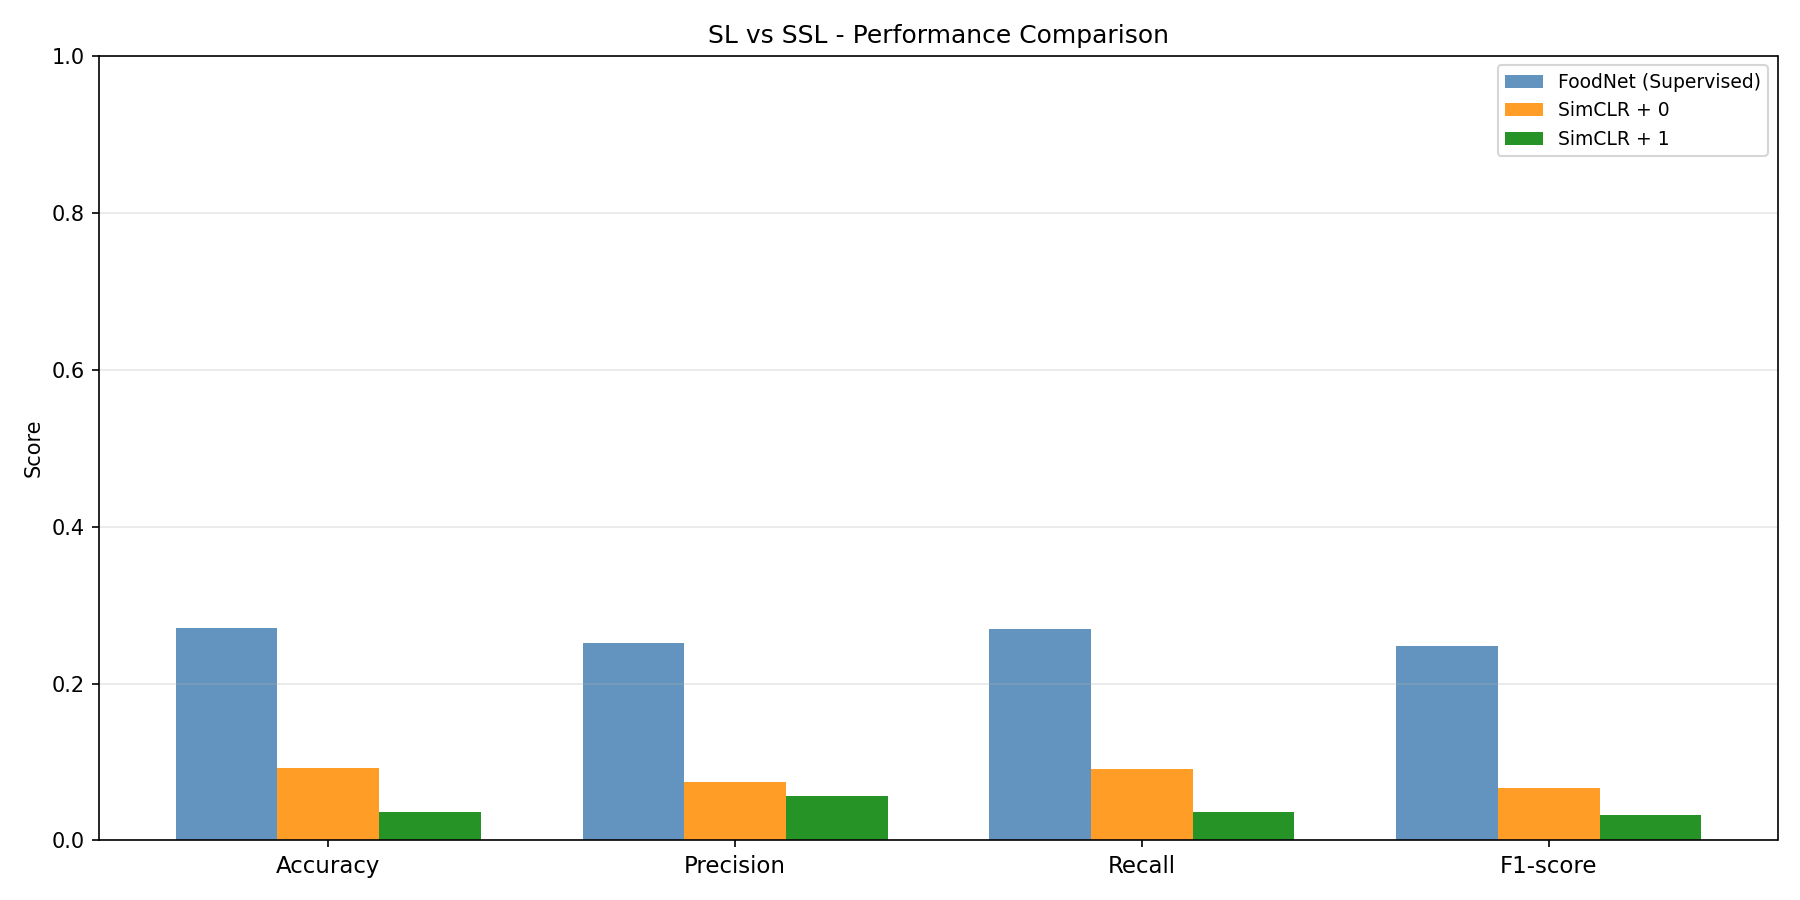

In [ ]:
import pandas as pd
comp = pd.read_csv(os.path.join(OUT_DIR, 'comparison_table.csv'))
print(comp.to_string(index=False))
display(IPImage(os.path.join(OUT_DIR, 'comparison_chart.png')))

## 8. Final Summary

In [ ]:
print('=== SUPERVISED LEARNING ===')
sl = pd.read_csv(os.path.join(OUT_DIR, 'sl_metrics.csv'))
print(sl.to_string(index=False))

print('\n=== SELF-SUPERVISED LEARNING ===')
ssl = pd.read_csv(os.path.join(OUT_DIR, 'ssl_metrics.csv'))
print(ssl.to_string())

print('\n=== FULL COMPARISON ===')
print(comp.to_string(index=False))

=== SUPERVISED LEARNING ===
 accuracy  precision   recall       f1
 0.270424   0.251349 0.269431 0.247333

=== SELF-SUPERVISED LEARNING ===
  Unnamed: 0  accuracy  precision    recall        f1
0        SVM  0.092008   0.074912  0.091673  0.067035
1        KNN  0.035825   0.056247  0.035707  0.032614

=== FULL COMPARISON ===
              Method  Accuracy  Precision   Recall  F1-score
FoodNet (Supervised)  0.270424   0.251349 0.269431  0.247333
          SimCLR + 0  0.092008   0.074912 0.091673  0.067035
          SimCLR + 1  0.035825   0.056247 0.035707  0.032614
